# 03 Cross-fault creep time series

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13. Takes ~15 min per track for the extraction (it reads
the 10 GB displacement cube window by window); the rest is seconds.
```

**What this notebook does.** At every 100 m crossing of the mapped Hayward
trace it takes the InSAR pixels on the WEST and EAST side within a fixed
cross-fault aperture and differences the two sides at every epoch:

$$ \mathrm{creep}(t) = \mathrm{median}(\mathrm{east\ LOS})(t) - \mathrm{median}(\mathrm{west\ LOS})(t) $$

This is done separately for the ascending (09157) and descending (11115)
frames on the RAW line-of-sight displacement. The west-east difference cancels
the reference datum and the per-date common-mode noise (Methods M3). The two
LOS series are then put on a common date grid and decomposed, crossing by
crossing, into fault-parallel (FP) and vertical (Up) displacement with the
local strike. The FP time series `fp_ts.csv` is THE input to event detection
(04), validation (05) and the alignment-array comparison (08).

Ported from `Hayward_DISP-S1/analysis/run08_extract_creep_profiles.py` and
`run09_decompose_creep.py`, plus the two supplementary figures
(`figS3_ratemask.py`, `figS4_acquisitions.py`). The maths is unchanged.

**Outputs** (`outputs/03_creep_timeseries/`):
- per track: `creep_ts_LOS_<track>.csv` (lat x decimal-year matrix, mm LOS),
  `creep_geom_<track>.csv` (mean incidence / azimuth per crossing),
  `creep_params_<track>.json`, `rate_deviation_<track>.csv`
- common grid: `asc_los_interp.csv`, `desc_los_interp.csv`, `fp_ts.csv`, `up_ts.csv`
- along-fault rates: `creep_rate_fp.csv`, `creep_rate_up.csv`; `decompose_params.json`
- `03_creep_stats.txt` and the registry rows `03_*`

**Figures**: S3 (the near-fault rate mask), S4 (real versus interpolated
epochs), and a QC plot of the along-fault creep rate.

**What to check when you run it.** The rate-mask sigma should be ~0.4 mm/yr on
both tracks with ~4% rejected; the common grid should have 423 dates with 277
where both tracks are real; the median FP creep rate should be ~4.7 mm/yr and
CFW1's crossing ~7 mm/yr. If the legacy sweep CSVs from Hayward_DISP-S1 are on disk,
the new LOS series must match them to numerical precision.

In [1]:
import os
import json

import insar_utils as utils
from TulePond_filepaths import (common_paths, insar_dic_list, creepmeters, unit, params,
                                dist_min, dist_max, x_width, min_points, coh_timeseries,
                                rate_nsigma, az_smooth_n, max_interp_gap_days, rate_smooth_km,
                                paths_out, repo_dir, data_dir)

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import h5py                                      # MintPy HDF5 products
from pyproj import Transformer                   # lon/lat -> UTM
from scipy.ndimage import gaussian_filter1d      # along-fault smoothing
import matplotlib.pyplot as plt

## Constants

The aperture, mask and smoothing choices come from `TulePond_filepaths.py` so
every notebook uses the same values; the reasons are in the assumptions
register. The few below are used only here.

In [2]:
notebook = "03_creep_timeseries"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

win_pix = 20              # local window half-size (px) read around each crossing
utm_epsg = 32610          # UTM 10N, the grid the frames live on
lat_min = 37.489475       # southern cutoff for reported creep rates: below it the data are
#                           too patchy and the fault splays into several strands
trend_window = 21         # crossings (~2 km) in the running median used to flag landslide crossings
trend_nsigma = 3.0        # a crossing whose FP rate departs from that trend by more than this is dropped
s1b_death = 2021.98       # Sentinel-1B failed 2021-12-23: 6-day sampling ends (Fig S4)

# Legacy products from Hayward_DISP-S1's aperture sweep (July/August 2026), used
# only to check that this port reproduces them. Absent on a clean machine: skipped.
legacy_dir = os.path.join(data_dir, "outputs", "sweep", f"ap{dist_min * 1000:.0f}-{dist_max * 1000:.0f}m_coh{coh_timeseries:g}_mp{min_points}")

print(f"aperture {dist_min * 1000:.0f}-{dist_max * 1000:.0f} m, along-strike +/-{x_width * 1000:.0f} m, "
      f"min {min_points} px per side, coherence {coh_timeseries}, rate mask {rate_nsigma:g} sigma")
print(f"tracks: " + ", ".join(f"{d['ORBIT_DIRECTION']} {d['Frame']}" for d in insar_dic_list))

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(*[d[k] for d in insar_dic_list for k in ("ts_file", "vel_file", "geo_file")],
           *[d["mask_file"][coh_timeseries] for d in insar_dic_list],
           common_paths["fault_profiles"])

aperture 30-150 m, along-strike +/-200 m, min 5 px per side, coherence 0.7, rate mask 3 sigma
tracks: ascending 09157, descending 11115
Registry for 03_creep_timeseries: run 9dbed82a, git nogit+


## LOAD and SHOW: the fault crossings and one track's inputs

`hayward_fault_profiles.csv` is the mapped trace resampled every 100 m with
the local cross-fault azimuth. The azimuth is smoothed with a 21-point rolling
median (2.1 km) before it sets the sampling direction, the same smoothing
notebook 02 used for the strike. Each crossing's window is then defined by two
unit vectors: `p` across the fault (positive = east side) and `q` along it.

In [3]:
prof = pd.read_csv(common_paths["fault_profiles"])
ll2utm = Transformer.from_crs("EPSG:4326", f"EPSG:{utm_epsg}", always_xy=True)
E_st, N_st = map(np.asarray, ll2utm.transform(prof["ft_lon"].values, prof["ft_lat"].values))
az_deg = pd.Series(prof["profile_az"].values).rolling(az_smooth_n, center=True, min_periods=3).median().to_numpy()
az = np.deg2rad(az_deg)
pe, pn = np.sin(az), np.cos(az)                          # cross-fault unit vector (toward the east side)
se, sn = np.sin(az + np.pi / 2), np.cos(az + np.pi / 2)  # along-fault unit vector

print(f"{len(prof)} crossings from {prof.ft_lat.min():.4f} N (south) to {prof.ft_lat.max():.4f} N (Point Pinole)")
print(f"cross-fault azimuth: raw {prof.profile_az.min():.1f} to {prof.profile_az.max():.1f}, "
      f"smoothed {np.nanmin(az_deg):.1f} to {np.nanmax(az_deg):.1f} deg")

# what one track's inputs look like
for dic in insar_dic_list:
    with h5py.File(dic["ts_file"], "r") as h:
        dates = [d.decode() for d in h["date"][:]]
        shape = h["timeseries"].shape
        a = h.attrs
        print(f"{dic['ORBIT_DIRECTION']} {dic['Frame']}: cube {shape} (dates x rows x cols), "
              f"{dates[0]} to {dates[-1]}, grid {a['X_STEP']} m EPSG {a['EPSG']}")
    with h5py.File(dic["mask_file"][coh_timeseries], "r") as h:
        m = h["mask"][:]
        print(f"   coherence-{coh_timeseries} mask: {100 * m.mean():.1f}% of pixels kept")

791 crossings from 37.4141 N (south) to 37.9915 N (Point Pinole)
cross-fault azimuth: raw 23.7 to 76.4, smoothed 45.8 to 68.2 deg
ascending 09157: cube (344, 3048, 2333) (dates x rows x cols), 20160729 to 20251221, grid 30.0 m EPSG 32610
   coherence-0.7 mask: 30.6% of pixels kept
descending 11115: cube (359, 3048, 2333) (dates x rows x cols), 20160903 to 20251215, grid 30.0 m EPSG 32610
   coherence-0.7 mask: 37.7% of pixels kept


## Extraction, one crossing at a time

`station_window` finds the west and east pixels of one crossing: coherent,
with a finite rate, within `x_width` along strike and between `dist_min` and
`dist_max` across. `extract_track` runs two passes over the crossings:

1. **The rate mask.** Every pixel's LOS rate is expressed as its deviation
   from the median rate of ITS OWN SIDE at that crossing. Fault creep is a
   difference BETWEEN sides, so it does not enter, and the pooled deviation
   population is centred on zero along the whole fault. One robust sigma per
   track; pixels beyond `rate_nsigma` sigma (landslides, quarries, their
   edges) are rejected.
2. **The difference.** For the surviving pixels, read the displacement cube
   in the crossing's window, take the median of each side per epoch, and
   difference east minus west. The mean incidence and azimuth over the
   survivors are kept for the decomposition.

In [4]:
def station_window(T, i):
    """Window bounds and the WEST / EAST pixel masks of crossing i. None if the
    crossing is off the frame or has fewer than min_points pixels on a side."""
    c0 = int(round((E_st[i] - T["gx0"]) / T["dx"]))
    r0 = int(round((N_st[i] - T["gy0"]) / T["dy"]))
    ra, rb = max(0, r0 - T["win"]), min(T["ny"], r0 + T["win"] + 1)
    ca, cb = max(0, c0 - T["win"]), min(T["nx"], c0 + T["win"] + 1)
    if rb - ra < 3 or cb - ca < 3:                       # crossing off the frame
        return None
    # signed cross-fault (p) and along-fault (q) distance of every window pixel, km
    cc, rr = np.meshgrid(np.arange(ca, cb), np.arange(ra, rb))
    E = T["gx0"] + cc * T["dx"]
    N = T["gy0"] + rr * T["dy"]
    p = ((E - E_st[i]) * pe[i] + (N - N_st[i]) * pn[i]) / 1000.0
    q = ((E - E_st[i]) * se[i] + (N - N_st[i]) * sn[i]) / 1000.0
    mwin = T["mask"][ra:rb, ca:cb] & np.isfinite(T["vel"][ra:rb, ca:cb])
    in_along = np.abs(q) <= x_width
    west = mwin & in_along & (p < -dist_min) & (p > -dist_max)
    east = mwin & in_along & (p > dist_min) & (p < dist_max)
    if west.sum() < min_points or east.sum() < min_points:
        return None
    return dict(ra=ra, rb=rb, ca=ca, cb=cb, west=west, east=east)


def extract_track(dic):
    """Cross-fault LOS creep series for one frame, with the rate mask applied.
    Writes the four per-track files and returns the mask numbers."""
    track = dic["ORBIT_DIRECTION"]
    with h5py.File(dic["geo_file"], "r") as h:
        # incidence/azimuth are stored float16; cast up before any arithmetic
        inc = h["incidenceAngle"][:].astype(np.float64)
        azi = h["azimuthAngle"][:].astype(np.float64)
    with h5py.File(dic["mask_file"][coh_timeseries], "r") as h:
        mask = h["mask"][:].astype(bool)
    with h5py.File(dic["vel_file"], "r") as h:
        vel = h["velocity"][:].astype(np.float64) * unit        # mm/yr, the rate-mask discriminator
    tsf = h5py.File(dic["ts_file"], "r")                          # the cube stays on disk; read per window
    a = tsf.attrs
    dates = [d.decode() for d in tsf["date"][:]]
    dec = np.array([utils.date_to_decimal_year(d) for d in dates])
    T = dict(ts=tsf["timeseries"], inc=inc, azi=azi, mask=mask, vel=vel,
             gx0=float(a["X_FIRST"]), gy0=float(a["Y_FIRST"]), dx=float(a["X_STEP"]), dy=float(a["Y_STEP"]),
             ny=inc.shape[0], nx=inc.shape[1],
             win=max(win_pix, int(np.ceil(dist_max * 1000.0 / abs(float(a["X_STEP"]))) + 3)))

    # --- pass 1: window per crossing + the pooled rate-deviation population ---
    print(f"[{track}] pass 1: windows and rate deviations ...")
    wins, devs = {}, []
    for i in range(len(prof)):
        w = station_window(T, i)
        if w is None:
            continue
        wins[i] = w
        v_win = vel[w["ra"]:w["rb"], w["ca"]:w["cb"]]
        for side in ("west", "east"):
            v = v_win[w[side]]
            devs.append(v - np.median(v))
    dev_pop = np.concatenate(devs)
    sigma = utils.robust_sigma(dev_pop)
    thr = rate_nsigma * sigma

    # --- pass 2: reject fast pixels, difference the surviving side medians ---
    print(f"[{track}] pass 2: reading the cube at {len(wins)} crossings ...")
    rows, geom = {}, {}
    n_rej_px = n_tot_px = n_drop = 0
    for i, w in wins.items():
        v_win = vel[w["ra"]:w["rb"], w["ca"]:w["cb"]]
        keep = {}
        for side in ("west", "east"):
            sel = w[side]
            v = v_win[sel]
            good = np.abs(v - np.median(v)) <= thr
            n_tot_px += int(sel.sum()); n_rej_px += int((~good).sum())
            survivor = np.zeros_like(sel)
            survivor[sel] = good
            keep[side] = survivor
        if keep["west"].sum() < min_points or keep["east"].sum() < min_points:
            n_drop += 1
            continue
        ts_win = T["ts"][:, w["ra"]:w["rb"], w["ca"]:w["cb"]] * unit          # m -> mm
        w_avg = np.nanmedian(ts_win[:, keep["west"]], axis=1)
        e_avg = np.nanmedian(ts_win[:, keep["east"]], axis=1)
        rows[float(prof["ft_lat"][i])] = e_avg - w_avg
        both = keep["west"] | keep["east"]
        geom[float(prof["ft_lat"][i])] = (float(np.nanmean(inc[w["ra"]:w["rb"], w["ca"]:w["cb"]][both])),
                                          float(np.nanmean(azi[w["ra"]:w["rb"], w["ca"]:w["cb"]][both])))
    tsf.close()

    # --- write: the lat x decimal-year matrix (rows south -> north), geometry, params, deviations ---
    mat = pd.DataFrame.from_dict(rows, orient="index", columns=np.round(dec, 4))
    mat.index.name = "lat"
    mat.sort_index().to_csv(os.path.join(out_dir, f"creep_ts_LOS_{track}.csv"))
    g = pd.DataFrame.from_dict(geom, orient="index", columns=["inc_deg", "azi_deg"])
    g.index.name = "lat"
    g.sort_index().to_csv(os.path.join(out_dir, f"creep_geom_{track}.csv"))
    with open(os.path.join(out_dir, f"creep_params_{track}.json"), "w") as fh:
        json.dump(dict(coh=coh_timeseries, dist_min=dist_min, dist_max=dist_max, x_width=x_width,
                       min_points=min_points, rate_nsigma=rate_nsigma), fh, indent=1)
    pd.DataFrame({"rate_deviation_mm_yr": dev_pop}).to_csv(os.path.join(out_dir, f"rate_deviation_{track}.csv"), index=False)

    rej_pct = 100.0 * n_rej_px / n_tot_px
    print(f"[{track}] {len(rows)}/{len(prof)} crossings, {len(dates)} dates")
    print(f"          rate mask: sigma {sigma:.3f} mm/yr, cut +/-{thr:.3f} ({rate_nsigma:g} sigma) -> "
          f"{rej_pct:.1f}% of pixels rejected, {n_drop} crossings dropped, max |dev| {np.abs(dev_pop).max():.1f}")
    print("")
    return dict(track=track, n_crossings=len(rows), n_dates=len(dates), dec=dec, sigma=sigma, thr=thr,
                rej_pct=rej_pct, n_px=dev_pop.size, max_dev=float(np.abs(dev_pop).max()), n_drop=n_drop)

## RUN the extraction (gated)

The cube read takes ~15 minutes per track. If the per-track files already
exist and were made with the same parameters, the cell reuses them and only
recomputes the mask numbers from the saved deviation population. Delete the
files (or change a parameter) to force a re-run.

In [5]:
params_now = dict(coh=coh_timeseries, dist_min=dist_min, dist_max=dist_max, x_width=x_width,
                  min_points=min_points, rate_nsigma=rate_nsigma)
mask_stats = {}
for dic in insar_dic_list:
    track = dic["ORBIT_DIRECTION"]
    pfile = os.path.join(out_dir, f"creep_params_{track}.json")
    done = os.path.exists(pfile) and json.load(open(pfile)) == params_now \
        and os.path.exists(os.path.join(out_dir, f"creep_ts_LOS_{track}.csv"))
    if done:
        print(f"[{track}] extraction already on disk with these parameters; reusing")
        dev_pop = pd.read_csv(os.path.join(out_dir, f"rate_deviation_{track}.csv"))["rate_deviation_mm_yr"].to_numpy()
        mat = pd.read_csv(os.path.join(out_dir, f"creep_ts_LOS_{track}.csv"), index_col=0)
        sigma = utils.robust_sigma(dev_pop); thr = rate_nsigma * sigma
        mask_stats[track] = dict(track=track, n_crossings=len(mat), n_dates=mat.shape[1],
                                 dec=mat.columns.astype(float).to_numpy(), sigma=sigma, thr=thr,
                                 rej_pct=100.0 * np.mean(np.abs(dev_pop) > thr), n_px=dev_pop.size,
                                 max_dev=float(np.abs(dev_pop).max()), n_drop=np.nan)
    else:
        mask_stats[track] = extract_track(dic)

[ascending] extraction already on disk with these parameters; reusing
[descending] extraction already on disk with these parameters; reusing


## CHECK: parity with the legacy products, and one crossing by hand

Two plain checks. If the July/August products from `Hayward_DISP-S1` are on
disk, the new LOS matrices must equal them (same code, same data). Then one
crossing near CFW1 is redone in a few lines straight from the cube so the
median-difference is visible without the function machinery.

In [6]:
def load_los(path):
    d = pd.read_csv(path, index_col=0)
    d.columns = d.columns.astype(float)
    d.index = d.index.astype(float)
    return d


for dic in insar_dic_list:
    track = dic["ORBIT_DIRECTION"]
    new = load_los(os.path.join(out_dir, f"creep_ts_LOS_{track}.csv"))
    old_path = os.path.join(legacy_dir, f"creep_ts_LOS_{track}.csv")
    if os.path.exists(old_path):
        old = load_los(old_path)
        assert new.shape == old.shape, f"{track}: {new.shape} crossings x dates, legacy {old.shape}"
        diff = np.nanmax(np.abs(new.values - old.values))
        print(f"[{track}] legacy parity: same {new.shape} matrix, max |difference| {diff:.2e} mm")
        assert diff < 1e-6, f"{track}: the new LOS series differ from the legacy ones"
    else:
        print(f"[{track}] no legacy file at {old_path}; parity check skipped")

[ascending] legacy parity: same (656, 344) matrix, max |difference| 0.00e+00 mm
[descending] legacy parity: same (633, 359) matrix, max |difference| 0.00e+00 mm


In [7]:
# one crossing by hand: the crossing nearest CFW1, ascending, at the last epoch
dic = insar_dic_list[0]
cfw1_lat = [c[1] for c in creepmeters if c[0] == "CFW1"][0]
i = int(np.argmin(np.abs(prof["ft_lat"].values - cfw1_lat)))
with h5py.File(dic["geo_file"], "r") as h:
    ny, nx = h["incidenceAngle"].shape
with h5py.File(dic["mask_file"][coh_timeseries], "r") as h:
    mask = h["mask"][:].astype(bool)
with h5py.File(dic["vel_file"], "r") as h:
    vel = h["velocity"][:].astype(np.float64) * unit
with h5py.File(dic["ts_file"], "r") as h:
    a = h.attrs
    T = dict(mask=mask, vel=vel, gx0=float(a["X_FIRST"]), gy0=float(a["Y_FIRST"]), dx=float(a["X_STEP"]),
             dy=float(a["Y_STEP"]), ny=ny, nx=nx, win=win_pix)
    w = station_window(T, i)
    last = h["timeseries"][-1, w["ra"]:w["rb"], w["ca"]:w["cb"]] * unit
by_hand = np.nanmedian(last[w["east"]]) - np.nanmedian(last[w["west"]])
from_file = load_los(os.path.join(out_dir, "creep_ts_LOS_ascending.csv")).loc[float(prof["ft_lat"][i])].iloc[-1]
print(f"crossing {i} at {prof.ft_lat[i]:.4f} N (nearest CFW1), ascending, last epoch:")
print(f"   {w['west'].sum()} west px, {w['east'].sum()} east px before the rate mask")
print(f"   east median - west median by hand = {by_hand:.3f} mm;  value in creep_ts_LOS_ascending.csv = {from_file:.3f} mm")
print("   (they differ only by the few pixels the rate mask removed)")

crossing 164 at 37.5321 N (nearest CFW1), ascending, last epoch:
   49 west px, 54 east px before the rate mask
   east median - west median by hand = -15.315 mm;  value in creep_ts_LOS_ascending.csv = -15.332 mm
   (they differ only by the few pixels the rate mask removed)


## Figure S3: the near-fault rate mask

The pooled deviation population per track on a log count axis, with the cut.
The tail beyond the cut is what is rejected: landslides, quarries and their
edges. The core is kept whatever the local creep rate, because creep is a
difference between sides and never enters a within-side deviation.

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_ratemask_ap30-150m_coh0.7_mp5_sw200m_nsigma3.png


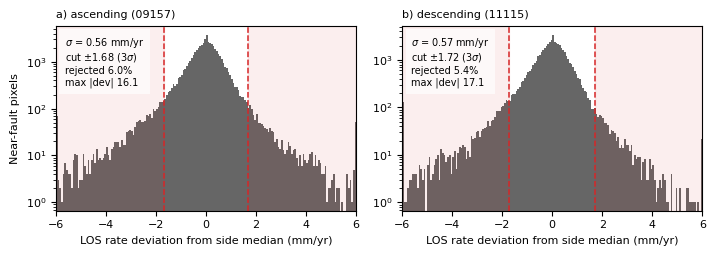

In [8]:
plt.rcParams.update({"font.size": 8})
lim, nbins = 6.0, 181
bins = np.linspace(-lim, lim, nbins)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6))
for ax, dic, letter in zip(axes, insar_dic_list, "ab"):
    track = dic["ORBIT_DIRECTION"]
    r = mask_stats[track]
    dev = pd.read_csv(os.path.join(out_dir, f"rate_deviation_{track}.csv"))["rate_deviation_mm_yr"].to_numpy()
    ax.hist(np.clip(dev, -lim, lim), bins=bins, color="0.4", log=True)     # clipped into the end bins, not dropped
    for s in (-1, 1):
        ax.axvline(s * r["thr"], color="tab:red", lw=1.1, ls="--")
    ax.axvspan(-lim, -r["thr"], color="tab:red", alpha=0.08)
    ax.axvspan(r["thr"], lim, color="tab:red", alpha=0.08)
    ax.set_xlim(-lim, lim)
    ax.set_xlabel("LOS rate deviation from side median (mm/yr)")
    ax.set_title(f"{letter}) {track} ({dic['Frame']})", loc="left", fontsize=8)
    ax.text(0.03, 0.95, f"$\\sigma$ = {r['sigma']:.2f} mm/yr\ncut $\\pm${r['thr']:.2f} ({rate_nsigma:g}$\\sigma$)\n"
            f"rejected {r['rej_pct']:.1f}%\nmax |dev| {r['max_dev']:.1f}",
            transform=ax.transAxes, va="top", ha="left", fontsize=7,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7))
axes[0].set_ylabel("Near-fault pixels")
fig.tight_layout()
figS3 = os.path.join(fig_dir, f"figS_ratemask_{params}_nsigma{rate_nsigma:g}.png")
fig.savefig(figS3, dpi=300); fig.savefig(figS3.replace(".png", ".pdf"))
print("Saved figure to:", figS3)
plt.show()

## Common date grid: interpolate each track onto the union of dates

The decomposition needs both tracks at the same epochs. Each crossing is
interpolated against its REAL acquisition dates onto the union of both
tracks' dates within their overlap, but only across gaps shorter than
`max_interp_gap_days` (45 d): that bridges the 6, 12 and 24 day sampling and
a few missed acquisitions, and leaves the two genuine 2018 ascending breaks
(72 and 84 d) as honest NaN. Nothing is extrapolated. Crossings south of
`lat_min` are dropped here.

In [9]:
def interp_row(target_t, src_t, src_v):
    """One crossing onto target_t against its real dates; NaN inside gaps longer
    than max_interp_gap_days and outside the observed range."""
    out = np.full(len(target_t), np.nan)
    ok = np.isfinite(src_v)
    if ok.sum() < 2:
        return out
    st, sv = src_t[ok], src_v[ok]
    y = np.interp(target_t, st, sv)
    j = np.clip(np.searchsorted(st, target_t, side="right") - 1, 0, len(st) - 1)
    jn = np.clip(j + 1, 0, len(st) - 1)
    exact = np.isclose(target_t, st[j], atol=0.5 / 365.25)          # a real acquisition
    span_days = (st[jn] - st[j]) * 365.25
    inside = (target_t >= st[0] - 0.5 / 365.25) & (target_t <= st[-1] + 0.5 / 365.25)
    keep = inside & (exact | (span_days <= max_interp_gap_days))
    out[keep] = y[keep]
    return out


asc = load_los(os.path.join(out_dir, "creep_ts_LOS_ascending.csv"))
desc = load_los(os.path.join(out_dir, "creep_ts_LOS_descending.csv"))
t0 = max(asc.columns.min(), desc.columns.min())
t1 = min(asc.columns.max(), desc.columns.max())
common_t = np.array(sorted(set(asc.columns) | set(desc.columns)))
common_t = common_t[(common_t >= t0) & (common_t <= t1)]
lats_all = np.array(sorted(set(asc.index) & set(desc.index)))
lats = lats_all[lats_all >= lat_min]
print(f"crossings on both tracks: {len(lats_all)}; south of {lat_min}: {len(lats_all) - len(lats)} dropped, {len(lats)} kept")

interp = {}
for name, d in (("asc", asc), ("desc", desc)):
    M = np.full((len(lats), len(common_t)), np.nan)
    src_t = d.columns.values.astype(float)
    for i, la in enumerate(lats):
        M[i] = interp_row(common_t, src_t, d.loc[la].values)
    interp[name] = pd.DataFrame(M, index=lats, columns=common_t)
    interp[name].index.name = "lat"
print(f"common grid: {len(lats)} crossings x {len(common_t)} dates, {t0:.3f} to {t1:.3f}")

# which epochs are REAL on each track (an acquisition within half a day) and which are interpolated
real = {}
for name, d in (("asc", asc), ("desc", desc)):
    src_t = d.columns.values.astype(float)
    real[name] = np.array([np.min(np.abs(src_t - x)) < 0.5 / 365.25 for x in common_t])
both_real = real["asc"] & real["desc"]
print(f"both tracks real at {both_real.sum()} epochs; interpolated: asc {(~real['asc']).sum()} "
      f"({100 * (~real['asc']).mean():.0f}%), desc {(~real['desc']).sum()} ({100 * (~real['desc']).mean():.0f}%)")

crossings on both tracks: 610; south of 37.489475: 1 dropped, 609 kept
common grid: 609 crossings x 423 dates, 2016.672 to 2025.953
both tracks real at 277 epochs; interpolated: asc 82 (19%), desc 64 (15%)


## Decompose each crossing into fault-parallel and vertical

Per crossing, with the mean incidence and azimuth of the surviving pixels
(one pair per track, from `creep_geom_<track>.csv`) and the local strike
(smoothed cross-fault azimuth + 90), solve
$[d_{asc}, d_{desc}]^T = G\,[U, FP]^T$ by least squares at every epoch
(`utils.design_matrix_up_fp`, the design matrix pinned by the tests). FP is
positive along the strike bearing, so right-lateral creep is positive.

In [10]:
geom = {}
for dic, key in zip(insar_dic_list, ("asc", "desc")):
    g = pd.read_csv(os.path.join(out_dir, f"creep_geom_{dic['ORBIT_DIRECTION']}.csv"), index_col=0)
    geom[key] = (float(g["inc_deg"].mean()), float(g["azi_deg"].mean()))
    print(f"{dic['ORBIT_DIRECTION']}: mean incidence {geom[key][0]:.2f}, mean azimuth {geom[key][1]:.2f} deg")

plat = prof["ft_lat"].to_numpy(float)
strikes = az_deg[np.abs(plat[None, :] - lats[:, None]).argmin(axis=1)] + 90.0

U = np.full((len(lats), len(common_t)), np.nan)
FP = np.full((len(lats), len(common_t)), np.nan)
for i in range(len(lats)):
    G = utils.design_matrix_up_fp([geom["asc"][0], geom["desc"][0]], [geom["asc"][1], geom["desc"][1]], strikes[i])
    D = np.vstack([interp["asc"].values[i], interp["desc"].values[i]])        # (2, n epochs)
    ok = np.isfinite(D).all(axis=0)
    if ok.sum() == 0:
        continue
    sol = np.linalg.lstsq(G, D[:, ok], rcond=None)[0]
    U[i, ok], FP[i, ok] = sol[0], sol[1]
up = pd.DataFrame(U, index=lats, columns=common_t); up.index.name = "lat"
fp = pd.DataFrame(FP, index=lats, columns=common_t); fp.index.name = "lat"
print(f"decomposed {np.isfinite(FP).any(axis=1).sum()} crossings; G for a mid-fault crossing:")
print(utils.design_matrix_up_fp([geom["asc"][0], geom["desc"][0]], [geom["asc"][1], geom["desc"][1]],
                                float(np.median(strikes))).round(3), "  (columns U, FP)")

ascending: mean incidence 40.26, mean azimuth 99.95 deg
descending: mean incidence 44.13, mean azimuth 260.54 deg
decomposed 609 crossings; G for a mid-fault crossing:
[[ 0.763 -0.285]
 [ 0.718  0.497]]   (columns U, FP)


## Along-fault creep rate and the crossing-level landslide flag

A linear rate per crossing (`np.polyfit`, as in the legacy code). The pixel
rate mask removes landslide EDGES, but a landslide that dominates one side IS
that side's median; such crossings stand out as spikes against the smooth
along-fault trend. Crossings more than `trend_nsigma` robust sigma from a
21-crossing running median are dropped from every product. The surviving
profile is smoothed with a 0.5 km Gaussian that preserves the gaps.

In [11]:
def per_lat_rate(df):
    t = df.columns.values.astype(float)
    r = np.full(len(df), np.nan)
    for i in range(len(df)):
        y = df.values[i]
        m = np.isfinite(y)
        if m.sum() > 5:
            r[i] = np.polyfit(t[m], y[m], 1)[0]
    return r


def gaussian_smooth_km(rate, lats, sigma_km):
    """NaN-aware, gap-preserving Gaussian smoothing along the fault."""
    spacing_km = float(np.median(np.abs(np.diff(lats)))) * 111.19
    sig = max(sigma_km / spacing_km, 0.5)
    finite = np.isfinite(rate).astype(float)
    filled = np.where(finite > 0, rate, 0.0)
    num = gaussian_filter1d(filled, sig, mode="nearest")
    den = gaussian_filter1d(finite, sig, mode="nearest")
    out = np.divide(num, den, out=np.full_like(num, np.nan), where=den > 0.15)
    out[~np.isfinite(rate)] = np.nan
    return out


rate = per_lat_rate(fp)
trend = pd.Series(rate).rolling(trend_window, center=True, min_periods=5).median().to_numpy()
resid = rate - trend
trend_sig = utils.robust_sigma(resid)
flag = (np.abs(resid) > trend_nsigma * trend_sig) & np.isfinite(rate)
print(f"along-fault rejection: {flag.sum()}/{len(rate)} crossings dropped ({100 * flag.mean():.1f}%), "
      f"residual sigma {trend_sig:.2f} mm/yr")
for df in (interp["asc"], interp["desc"], up, fp):
    df.iloc[flag, :] = np.nan
rate_clean = np.where(flag, np.nan, rate)
rate_smooth = gaussian_smooth_km(rate_clean, lats, rate_smooth_km)
up_rate = per_lat_rate(up)
up_rate_smooth = gaussian_smooth_km(up_rate, lats, rate_smooth_km)

v = rate_clean[np.isfinite(rate_clean)]
print(f"FP creep rate: {v.size} valid crossings, median {np.median(v):.2f} mm/yr, "
      f"5-95% {np.percentile(v, 5):.2f} to {np.percentile(v, 95):.2f}, min-max {v.min():.2f} to {v.max():.2f}")
print(f"Up rate: median {np.nanmedian(up_rate):+.2f} mm/yr, 5-95% {np.nanpercentile(up_rate, 5):+.2f} to {np.nanpercentile(up_rate, 95):+.2f}")

along-fault rejection: 63/609 crossings dropped (10.3%), residual sigma 0.55 mm/yr
FP creep rate: 546 valid crossings, median 4.69 mm/yr, 5-95% 3.14 to 7.07, min-max 2.29 to 9.04
Up rate: median +0.07 mm/yr, 5-95% -0.92 to +1.14


In [12]:
# save every product of the common grid
interp["asc"].to_csv(os.path.join(out_dir, "asc_los_interp.csv"))
interp["desc"].to_csv(os.path.join(out_dir, "desc_los_interp.csv"))
fp.to_csv(os.path.join(out_dir, "fp_ts.csv"))
up.to_csv(os.path.join(out_dir, "up_ts.csv"))
pd.DataFrame({"lat": lats, "fp_creep_rate_mm_yr": rate_clean, "fp_creep_rate_raw": rate,
              "landslide_flag": flag.astype(int), "fp_creep_rate_smooth": rate_smooth, "strike_deg": strikes}
             ).to_csv(os.path.join(out_dir, "creep_rate_fp.csv"), index=False)
pd.DataFrame({"lat": lats, "up_rate_mm_yr": up_rate, "up_rate_smooth": up_rate_smooth}
             ).to_csv(os.path.join(out_dir, "creep_rate_up.csv"), index=False)
dparams = dict(max_interp_gap_days=max_interp_gap_days, rate_smooth_km=rate_smooth_km, lat_min=lat_min,
               trend_window=trend_window, trend_nsigma=trend_nsigma, **params_now)
with open(os.path.join(out_dir, "decompose_params.json"), "w") as fh:
    json.dump(dparams, fh, indent=1)
print("Saved fp_ts.csv, up_ts.csv, the interpolated LOS matrices and the rate profiles to:", out_dir)

Saved fp_ts.csv, up_ts.csv, the interpolated LOS matrices and the rate profiles to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/03_creep_timeseries


## CHECK: the creep rate at the creepmeters

The FP rate of the crossing nearest each creepmeter against the instrument's
rate over the same window (the full bootstrap comparison is notebook 04). The
numbers should agree to a few tenths of a millimetre a year; COZ1 is the
known exception (the InSAR misses part of its two large creep events).

In [13]:
km_of = utils.lat_to_km_map(common_paths["fault_profiles"])
print("crossing FP rate nearest each creepmeter (mm/yr):")
for code, la, lo, name in creepmeters:
    j = int(np.argmin(np.abs(lats - la)))
    cm = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code),
                                     date_start=t0, date_end=t1)
    cm_rate, _, _, _ = utils.linear_rate(cm["decimal_year"].values, cm["slip_mm"].values)
    print(f"  {code} ({name}, {km_of([la])[0]:.1f} km): InSAR {rate_clean[j]:5.2f}   creepmeter {cm_rate:5.2f}")

crossing FP rate nearest each creepmeter (mm/yr):


  CPP1 (Pinole Point, 0.3 km): InSAR  5.12   creepmeter  5.05


  CTM1 (Temescal, 20.1 km): InSAR  4.32   creepmeter  4.11


  COZ1 (Oakland Zoo, 32.2 km): InSAR  3.31   creepmeter  4.48


  CHP1 (Palisade Street, 44.5 km): InSAR  4.38   creepmeter  3.79


  CFW1 (Fremont, 62.6 km): InSAR  6.80   creepmeter  6.99


## QC figure: the along-fault creep-rate profile

Raw per-crossing rates (grey), flagged crossings (red), the smoothed profile
(black) and the creepmeter rates (blue). North (Point Pinole) on the left.

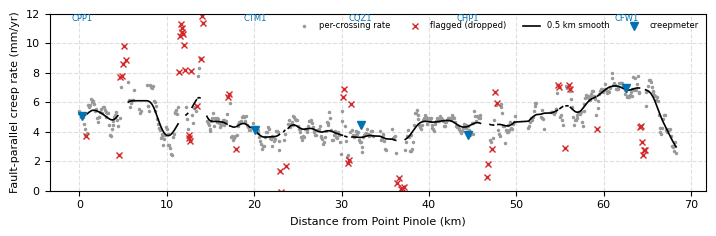

In [14]:
km = km_of(lats)
fig, ax = plt.subplots(figsize=(7.2, 2.4))
ax.plot(km, rate, ".", color="0.6", ms=3, label="per-crossing rate")
ax.plot(km[flag], rate[flag], "x", color="tab:red", ms=4, label="flagged (dropped)")
ax.plot(km, rate_smooth, "-", color="k", lw=1.2, label=f"{rate_smooth_km} km smooth")
for code, la, lo, name in creepmeters:
    cm = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code), date_start=t0, date_end=t1)
    ax.plot(km_of([la])[0], utils.linear_rate(cm["decimal_year"].values, cm["slip_mm"].values)[0],
            "v", color="#0072B2", ms=6, label="creepmeter" if code == "CPP1" else None)
    ax.text(km_of([la])[0], 11.5, code, ha="center", fontsize=6, color="#0072B2")
ax.set_xlabel("Distance from Point Pinole (km)"); ax.set_ylabel("Fault-parallel creep rate (mm/yr)")
ax.set_ylim(0, 12); ax.grid(True, ls="--", alpha=0.4); ax.legend(fontsize=6, frameon=False, ncol=4)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, f"qc03_creep_rate_profile_{params}.png"), dpi=300)
plt.show()

## Figure S4: real versus interpolated epochs

Which track is measured and which is filled in at each epoch of the common
grid. Before both orbits reached 6-day sampling they shared few dates, so
nearly every early epoch has one track interpolated. The 6-day start dates and
the window when both were acquired on the same days are computed from the
acquisition lists, not assumed.

common grid: 423 dates, Sep 2016 to Dec 2025
both orbits real       : 277 epochs
ascending interpolated : 82 (19%)
descending interpolated: 64 (15%)
acquisitions           : asc 344, desc 359
6-day sampling starts  : asc Oct 2018, desc Jun 2019
same-day window        : Mar 2020 -> Dec 2021 (2020.221-2021.98), 107 epochs, both real 99%, interpolated inside it: asc 1, desc 0
Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_acquisitions_ap30-150m_coh0.7_mp5_sw200m_gap45d.png


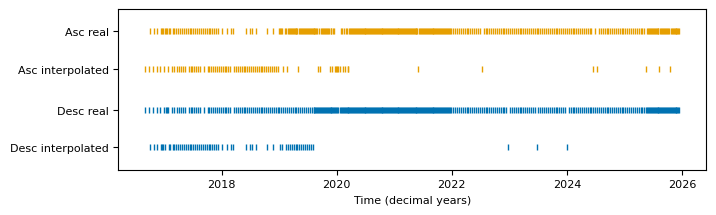

In [15]:
def month_year(dec_year):
    return utils.decimal_year_to_date(dec_year).strftime("%b %Y")


def sixday_start(dates, max_d=8.0, win=10):
    """First date from which sampling is sustained ~6-day (rolling median interval <= max_d)."""
    g = np.diff(dates) * 365.25
    roll = pd.Series(g).rolling(win, min_periods=win).median().to_numpy()
    ok = np.where(roll <= max_d)[0]
    return dates[ok[0] - win + 1] if len(ok) else None


def main_interp_block_end(times, real_flag, gap_d=180.0):
    """End of the main early run of interpolated epochs (a quiet stretch of gap_d closes it)."""
    interp_t = times[~real_flag]
    if len(interp_t) == 0:
        return times[0]
    brk = np.where(np.diff(interp_t) * 365.25 > gap_d)[0]
    return interp_t[brk[0]] if len(brk) else interp_t[-1]


acq = {"asc": mask_stats["ascending"]["dec"], "desc": mask_stats["descending"]["dec"]}
s_a, s_d = sixday_start(acq["asc"]), sixday_start(acq["desc"])
win0 = max(s_a, s_d, main_interp_block_end(common_t, real["asc"]), main_interp_block_end(common_t, real["desc"]))
win0 = float(common_t[common_t > win0].min())
inwin = (common_t >= win0) & (common_t <= s1b_death)

S4 = [f"common grid: {len(common_t)} dates, {month_year(common_t[0])} to {month_year(common_t[-1])}",
      f"both orbits real       : {both_real.sum()} epochs",
      f"ascending interpolated : {(~real['asc']).sum()} ({100 * (~real['asc']).mean():.0f}%)",
      f"descending interpolated: {(~real['desc']).sum()} ({100 * (~real['desc']).mean():.0f}%)",
      f"acquisitions           : asc {acq['asc'].size}, desc {acq['desc'].size}",
      f"6-day sampling starts  : asc {month_year(s_a)}, desc {month_year(s_d)}",
      f"same-day window        : {month_year(win0)} -> {month_year(s1b_death)} ({win0:.3f}-{s1b_death:g}), "
      f"{inwin.sum()} epochs, both real {both_real[inwin].mean():.0%}, interpolated inside it: "
      f"asc {(~real['asc'])[inwin].sum()}, desc {(~real['desc'])[inwin].sum()}"]
print("\n".join(S4))

fig, ax = plt.subplots(figsize=(7.2, 2.2))
ax.plot(common_t, real["asc"].astype(int) + 2.1, "|", ms=5, color="#E69F00")
ax.plot(common_t, real["desc"].astype(int), "|", ms=5, color="#0072B2")
ax.set_yticks([0, 1, 2.1, 3.1]); ax.set_yticklabels(["Desc interpolated", "Desc real", "Asc interpolated", "Asc real"])
ax.set_ylim(-0.6, 3.7); ax.set_xlabel("Time (decimal years)")
fig.tight_layout()
figS4 = os.path.join(fig_dir, f"figS_acquisitions_{params}_gap{max_interp_gap_days:.0f}d.png")
fig.savefig(figS4, dpi=300); fig.savefig(figS4.replace(".png", ".pdf"))
print("Saved figure to:", figS4)
plt.show()

## REGISTER

In [16]:
lines = ["03 CROSS-FAULT CREEP TIME SERIES",
         f"aperture {dist_min * 1000:.0f}-{dist_max * 1000:.0f} m, along-strike +/-{x_width * 1000:.0f} m, "
         f"min {min_points} px/side, coherence {coh_timeseries}", ""]
for track, r in mask_stats.items():
    lines.append(f"{track:<11} {r['n_crossings']} crossings, {r['n_dates']} dates; rate mask n={r['n_px']} px, "
                 f"sigma {r['sigma']:.3f} mm/yr, cut +/-{r['thr']:.3f}, rejected {r['rej_pct']:.1f}%, max|dev| {r['max_dev']:.1f}")
lines += ["", *S4, "",
          f"crossings analysed {len(rate)}, landslide-flagged {int(flag.sum())} (trend residual sigma {trend_sig:.2f} mm/yr)",
          f"FP creep rate (raw, cleaned): n {v.size}, median {np.median(v):.2f}, 5-95% {np.percentile(v, 5):.2f} to "
          f"{np.percentile(v, 95):.2f}, min-max {v.min():.2f} to {v.max():.2f} mm/yr",
          f"FP creep rate (smoothed {rate_smooth_km} km): median {np.nanmedian(rate_smooth):.2f}, "
          f"5-95% {np.nanpercentile(rate_smooth, 5):.2f} to {np.nanpercentile(rate_smooth, 95):.2f} mm/yr"]
sidecar = REG.sidecar("03_creep", lines)

for track, r in mask_stats.items():
    tag = track[:3]
    REG.register(f"03_n_crossings_{tag}", r["n_crossings"], "count", 0, where="M3", cell="extract", sidecar=sidecar)
    REG.register(f"03_n_acquisitions_{tag}", r["n_dates"], "count", 0, where="M1, M3", cell="extract", sidecar=sidecar)
    REG.register(f"03_rate_mask_sigma_{tag}", r["sigma"], "mm/yr", 2, where="M3, Fig S3", cell="extract", sidecar=sidecar)
    REG.register(f"03_rate_mask_cut_{tag}", r["thr"], "mm/yr", 2, where="M3, Fig S3", cell="extract", sidecar=sidecar)
    REG.register(f"03_rate_mask_rejected_pct_{tag}", r["rej_pct"], "pct", 1, where="M3, Fig S3", cell="extract", sidecar=sidecar)
    REG.register(f"03_rate_mask_maxdev_{tag}", r["max_dev"], "mm/yr", 1, where="M3, Fig S3", cell="extract", sidecar=sidecar)
REG.register("03_n_common_dates", len(common_t), "count", 0, where="M3, Fig S4", cell="common-grid", sidecar=sidecar)
REG.register("03_n_both_real", int(both_real.sum()), "count", 0, where="M3, Fig S4", cell="common-grid", sidecar=sidecar)
REG.register("03_interp_pct_asc", 100 * (~real["asc"]).mean(), "pct", 0, where="M3, Fig S4", cell="common-grid", sidecar=sidecar)
REG.register("03_interp_pct_desc", 100 * (~real["desc"]).mean(), "pct", 0, where="M3, Fig S4", cell="common-grid", sidecar=sidecar)
REG.register("03_window_start", t0, "decyear", 3, where="M3", cell="common-grid", sidecar=sidecar)
REG.register("03_window_end", t1, "decyear", 3, where="M3", cell="common-grid", sidecar=sidecar)
REG.register("03_sixday_start_asc", month_year(s_a), "date", 0, where="M3", cell="figS4", sidecar=sidecar)
REG.register("03_sixday_start_desc", month_year(s_d), "date", 0, where="M3", cell="figS4", sidecar=sidecar)
REG.register("03_sameday_window_epochs", int(inwin.sum()), "count", 0, where="M3", cell="figS4", sidecar=sidecar)
REG.register("03_n_crossings_common", len(rate), "count", 0, where="M3", cell="decompose", sidecar=sidecar)
REG.register("03_n_landslide_flagged", int(flag.sum()), "count", 0, where="M3", cell="landslide-flag", sidecar=sidecar)
REG.register("03_landslide_flagged_pct", 100 * flag.mean(), "pct", 0, where="M3", cell="landslide-flag", sidecar=sidecar)
REG.register("03_rate_median_mm_yr", np.median(v), "mm/yr", 2, where="Results", cell="rate-profile", sidecar=sidecar)
REG.register("03_rate_p5_mm_yr", np.percentile(v, 5), "mm/yr", 2, where="Results", cell="rate-profile", sidecar=sidecar)
REG.register("03_rate_p95_mm_yr", np.percentile(v, 95), "mm/yr", 2, where="Results", cell="rate-profile", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/03_creep_timeseries/03_creep_stats.txt
  registered 03_n_crossings_asc = 656 count  -> M3
  registered 03_n_acquisitions_asc = 344 count  -> M1, M3
  registered 03_rate_mask_sigma_asc = 0.56 mm/yr  -> M3, Fig S3
  registered 03_rate_mask_cut_asc = 1.68 mm/yr  -> M3, Fig S3
  registered 03_rate_mask_rejected_pct_asc = 6.0 pct  -> M3, Fig S3
  registered 03_rate_mask_maxdev_asc = 16.1 mm/yr  -> M3, Fig S3
  registered 03_n_crossings_des = 633 count  -> M3
  registered 03_n_acquisitions_des = 359 count  -> M1, M3
  registered 03_rate_mask_sigma_des = 0.57 mm/yr  -> M3, Fig S3
  registered 03_rate_mask_cut_des = 1.72 mm/yr  -> M3, Fig S3
  registered 03_rate_mask_rejected_pct_des = 5.4 pct  -> M3, Fig S3
  registered 03_rate_mask_maxdev_des = 17.1 mm/yr  -> M3, Fig S3
  registered 03_n_common_dates = 423 count  -> M3, Fig S4
  registered 03_n_both_real = 277 count  -> M3, Fig S4
  registered 03_interp_pct_asc = 19 pct  ->

  registered 03_sameday_window_epochs = 107 count  -> M3
  registered 03_n_crossings_common = 609 count  -> M3
  registered 03_n_landslide_flagged = 63 count  -> M3
  registered 03_landslide_flagged_pct = 10 pct  -> M3
  registered 03_rate_median_mm_yr = 4.69 mm/yr  -> Results
  registered 03_rate_p5_mm_yr = 3.14 mm/yr  -> Results
  registered 03_rate_p95_mm_yr = 7.07 mm/yr  -> Results
Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'